# E-Commerce Customer Analysis

### Objectives
- Predict customer spending
- Classify recent purchase behavior
- Segment customers into different groups

#need to add outliers and inconsistency in the data and normalization etc

##Import Libraries and Load Dataset

In [14]:
import pandas as pd

file_path = '/content/drive/MyDrive/E-commerce Customer Behavior - Sheet1.csv'

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (350, 11)


,Customer ID,Gender,Age,City,Membership Type,Total Spend,Items Purchased,Average Rating,Discount Applied,Days Since Last Purchase,Satisfaction Level
0,101,Female,29,New York,Gold,1120.20,14,4.6,True,25,Satisfied
1,102,Male,34,Los Angeles,Silver,780.50,11,4.1,False,18,Neutral
2,103,Female,43,Chicago,Bronze,510.75,9,3.4,True,42,Unsatisfied
3,104,Male,30,San Francisco,Gold,1480.30,19,4.7,False,12,Satisfied
4,105,Male,27,Miami,Silver,720.40,13,4.0,True,55,Unsatisfied


In [15]:
print("Dataset Information:")
df.info()

print("\nDataset Shape:")
print(df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nStatistical Summary:")
display(df.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 350 entries, 0 to 349
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Customer ID               350 non-null    int64  
 1   Gender                    350 non-null    object 
 2   Age                       350 non-null    int64  
 3   City                      350 non-null    object 
 4   Membership Type           350 non-null    object 
 5   Total Spend               350 non-null    float64
 6   Items Purchased           350 non-null    int64  
 7   Average Rating            350 non-null    float64
 8   Discount Applied          350 non-null    bool   
 9   Days Since Last Purchase  350 non-null    int64  
 10  Satisfaction Level        348 non-null    object 
dtypes: bool(1), float64(2), int64(4), object(4)
memory usage: 27.8+ KB

Dataset Shape:
(350, 11)

First 5 Rows:


,Customer ID,Gender,Age,City,Membership Type,Total Spend,Items Purchased,Average Rating,Discount Applied,Days Since Last Purchase,Satisfaction Level
0,101,Female,29,New York,Gold,1120.20,14,4.6,True,25,Satisfied
1,102,Male,34,Los Angeles,Silver,780.50,11,4.1,False,18,Neutral
2,103,Female,43,Chicago,Bronze,510.75,9,3.4,True,42,Unsatisfied
3,104,Male,30,San Francisco,Gold,1480.30,19,4.7,False,12,Satisfied
4,105,Male,27,Miami,Silver,720.40,13,4.0,True,55,Unsatisfied



Statistical Summary:


,Customer ID,Age,Total Spend,Items Purchased,Average Rating,Days Since Last Purchase
count,350.000000,350.000000,350.000000,350.000000,350.000000,350.000000
mean,275.500000,33.597143,845.381714,12.600000,4.019143,26.588571
std,101.180532,4.870882,362.058695,4.155984,0.580539,13.440813
min,101.000000,26.000000,410.800000,7.000000,3.000000,9.000000
25%,188.250000,30.000000,502.000000,9.000000,3.500000,15.000000
50%,275.500000,32.500000,775.200000,12.000000,4.100000,23.000000
75%,362.750000,37.000000,1160.600000,15.000000,4.500000,38.000000
max,450.000000,43.000000,1520.100000,21.000000,4.900000,63.000000


In [ ]:
df.shape

(350, 11)

-----Dataset Structure-----

In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 350 entries, 0 to 349
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Customer ID               350 non-null    int64  
 1   Gender                    350 non-null    object 
 2   Age                       350 non-null    int64  
 3   City                      350 non-null    object 
 4   Membership Type           350 non-null    object 
 5   Total Spend               350 non-null    float64
 6   Items Purchased           350 non-null    int64  
 7   Average Rating            350 non-null    float64
 8   Discount Applied          350 non-null    bool   
 9   Days Since Last Purchase  350 non-null    int64  
 10  Satisfaction Level        348 non-null    object 
dtypes: bool(1), float64(2), int64(4), object(4)
memory usage: 27.8+ KB


##Data Cleaning

-----Missing Values-----

In [17]:
df.isnull().sum()

,0
Customer ID,0
Gender,0
Age,0
City,0
Membership Type,0
Total Spend,0
Items Purchased,0
Average Rating,0
Discount Applied,0
Days Since Last Purchase,0


-----Handle Missing Values-----

In [18]:
df['Satisfaction Level'] = df['Satisfaction Level'].fillna(
    df['Satisfaction Level'].mode()[0]
)

print("Missing values after treatment:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values after treatment:
Customer ID                 0
Gender                      0
Age                         0
City                        0
Membership Type             0
Total Spend                 0
Items Purchased             0
Average Rating              0
Discount Applied            0
Days Since Last Purchase    0
Satisfaction Level          0
dtype: int64

Total missing values: 0


In [19]:
df.isnull().sum()

,0
Customer ID,0
Gender,0
Age,0
City,0
Membership Type,0
Total Spend,0
Items Purchased,0
Average Rating,0
Discount Applied,0
Days Since Last Purchase,0


-----Duplicate Rows-----

In [20]:
df.duplicated().sum()

np.int64(0)

-----Checking Actual Values-----

In [21]:
df.describe()

,Customer ID,Age,Total Spend,Items Purchased,Average Rating,Days Since Last Purchase
count,350.000000,350.000000,350.000000,350.000000,350.000000,350.000000
mean,275.500000,33.597143,845.381714,12.600000,4.019143,26.588571
std,101.180532,4.870882,362.058695,4.155984,0.580539,13.440813
min,101.000000,26.000000,410.800000,7.000000,3.000000,9.000000
25%,188.250000,30.000000,502.000000,9.000000,3.500000,15.000000
50%,275.500000,32.500000,775.200000,12.000000,4.100000,23.000000
75%,362.750000,37.000000,1160.600000,15.000000,4.500000,38.000000
max,450.000000,43.000000,1520.100000,21.000000,4.900000,63.000000


-----Checking categorical inconsistencies-----

In [22]:
categorical_cols = [
    'Gender',
    'City',
    'Membership Type',
    'Satisfaction Level'
]

for col in categorical_cols:
    print(f"\nUnique values in {col}:")
    print(df[col].unique())


Unique values in Gender:
['Female' 'Male']

Unique values in City:
['New York' 'Los Angeles' 'Chicago' 'San Francisco' 'Miami' 'Houston']

Unique values in Membership Type:
['Gold' 'Silver' 'Bronze']

Unique values in Satisfaction Level:
['Satisfied' 'Neutral' 'Unsatisfied']


-----checking numerical values and their ranges------

In [23]:
numerical_cols = [
    'Age',
    'Total Spend',
    'Items Purchased',
    'Average Rating',
    'Days Since Last Purchase'
]

print(df[numerical_cols].describe())

              Age  Total Spend  Items Purchased  Average Rating  \
count  350.000000   350.000000       350.000000      350.000000   
mean    33.597143   845.381714        12.600000        4.019143   
std      4.870882   362.058695         4.155984        0.580539   
min     26.000000   410.800000         7.000000        3.000000   
25%     30.000000   502.000000         9.000000        3.500000   
50%     32.500000   775.200000        12.000000        4.100000   
75%     37.000000  1160.600000        15.000000        4.500000   
max     43.000000  1520.100000        21.000000        4.900000   

       Days Since Last Purchase  
count                350.000000  
mean                  26.588571  
std                   13.440813  
min                    9.000000  
25%                   15.000000  
50%                   23.000000  
75%                   38.000000  
max                   63.000000  


-----IQR Detection-----

In [24]:
numerical_cols = [
    'Age',
    'Total Spend',
    'Items Purchased',
    'Average Rating',
    'Days Since Last Purchase'
]

for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print(f"\n{col}")
    print("Number of outliers:", len(outliers))


Age
Number of outliers: 0

Total Spend
Number of outliers: 0

Items Purchased
Number of outliers: 0

Average Rating
Number of outliers: 0

Days Since Last Purchase
Number of outliers: 0


-----Check Categorical Values-----

In [25]:
print("Gender:")
print(df['Gender'].value_counts())

print("\nCity:")
print(df['City'].value_counts())

print("\nMembership Type:")
print(df['Membership Type'].value_counts())

print("\nDiscount Applied:")
print(df['Discount Applied'].value_counts())

print("\nSatisfaction Level:")
print(df['Satisfaction Level'].value_counts())

Gender:
Gender
Female    175
Male      175
Name: count, dtype: int64

City:
City
New York         59
Los Angeles      59
Chicago          58
San Francisco    58
Miami            58
Houston          58
Name: count, dtype: int64

Membership Type:
Membership Type
Gold      117
Silver    117
Bronze    116
Name: count, dtype: int64

Discount Applied:
Discount Applied
True     175
False    175
Name: count, dtype: int64

Satisfaction Level:
Satisfaction Level
Satisfied      127
Unsatisfied    116
Neutral        107
Name: count, dtype: int64


-----Relationship b/w numerical values-----

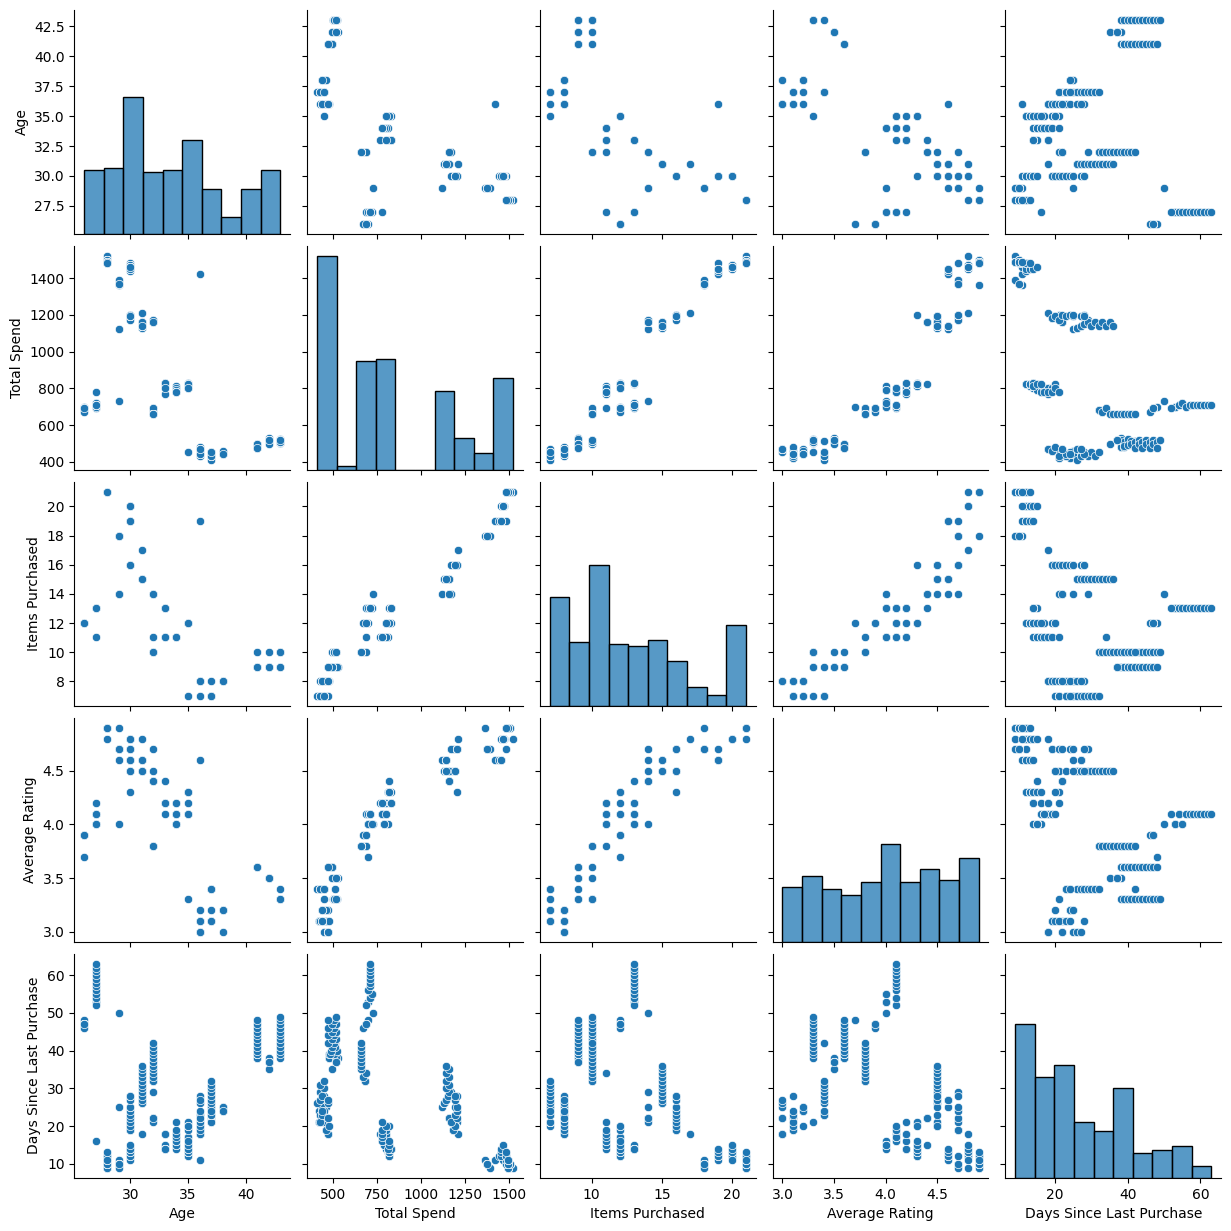

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.pairplot(
    df[['Age', 'Total Spend', 'Items Purchased',
        'Average Rating', 'Days Since Last Purchase']]
)

plt.show()

-----Correlation Matrix-----

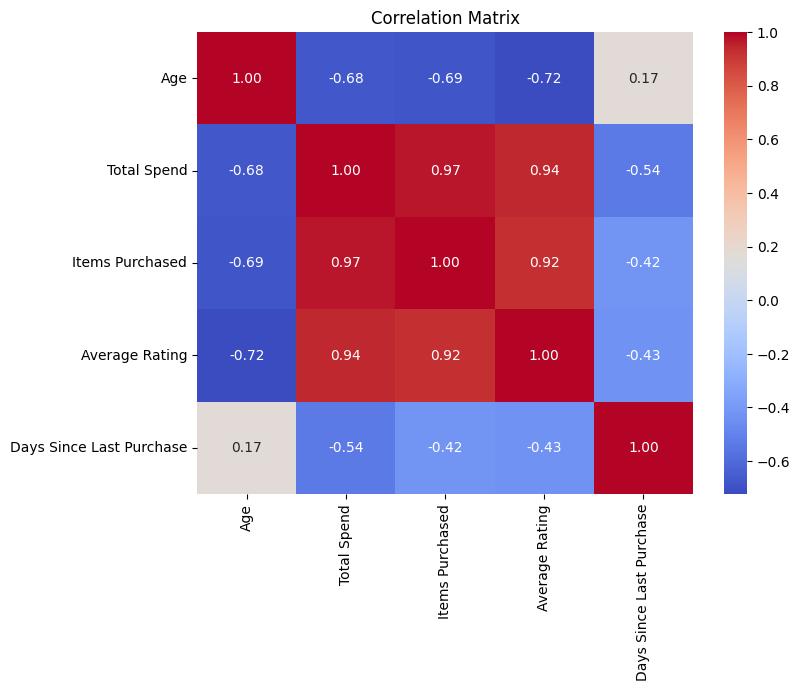

In [27]:
plt.figure(figsize=(8, 6))

corr = df[['Age', 'Total Spend', 'Items Purchased',
           'Average Rating', 'Days Since Last Purchase']].corr()

sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Matrix')
plt.show()

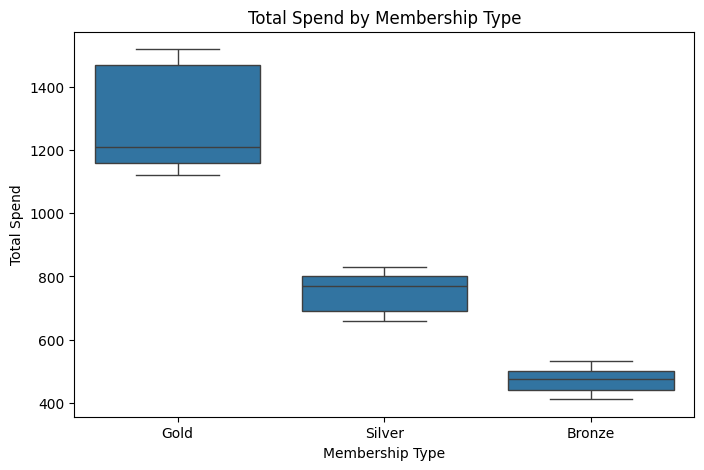

In [28]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x='Membership Type',
    y='Total Spend',
    data=df
)

plt.title('Total Spend by Membership Type')
plt.xlabel('Membership Type')
plt.ylabel('Total Spend')

plt.show()

-----Customer satisfaction related to total spend-----

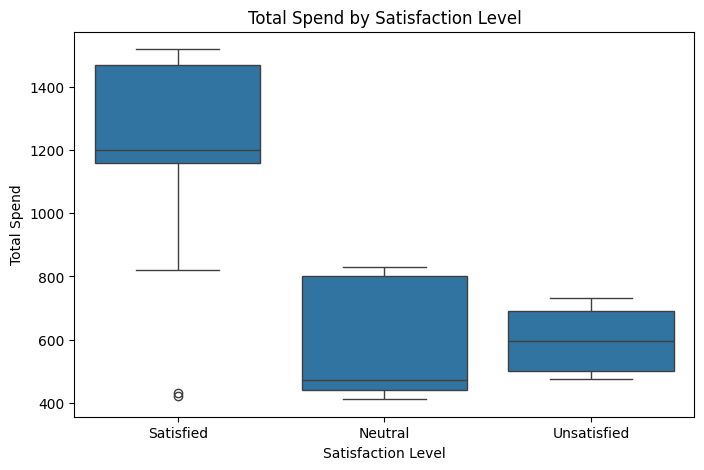

In [29]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x='Satisfaction Level',
    y='Total Spend',
    data=df
)

plt.title('Total Spend by Satisfaction Level')
plt.xlabel('Satisfaction Level')
plt.ylabel('Total Spend')

plt.show()

-----Average spending by City-----

In [30]:
city_spend = df.groupby('City')['Total Spend'].mean().sort_values(ascending=False)

print(city_spend)

City
San Francisco    1459.772414
New York         1165.035593
Los Angeles       805.491525
Miami             690.389655
Chicago           499.882759
Houston           446.894828
Name: Total Spend, dtype: float64


-----MODEL 1=Step 1:Total Spend Prediction-----

In [31]:
# Features (X) and target (y)

X = df[
    ['Age',
     'Items Purchased',
     'Average Rating',
     'Days Since Last Purchase',
     'Membership Type',
     'Gender',
     'City',
     'Discount Applied']
]

y = df['Total Spend']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (350, 8)
Target shape: (350,)


-----Step 2:Split the data ito training and testing data-----

In [32]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (280, 8)
Testing data: (70, 8)


-----Step 3:Encode the categorical features-----

In [33]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_features = [
    'Membership Type',
    'Gender',
    'City'
]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'),
         categorical_features)
    ],
    remainder='passthrough'
)

X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

print("Encoded training shape:", X_train_encoded.shape)
print("Encoded testing shape:", X_test_encoded.shape)

Encoded training shape: (280, 16)
Encoded testing shape: (70, 16)


-----Step 4:Train Linear Regression-----

In [34]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()

lr_model.fit(X_train_encoded, y_train)

y_pred_lr = lr_model.predict(X_test_encoded)

print("First 5 predictions:")
print(y_pred_lr[:5])

First 5 predictions:
[ 818.00011182 1145.83831724  701.04045266  837.39446228  434.4089721 ]


-----Step 5:Evaluate the Linear Regression model-----

In [35]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred_lr)
mse = mean_squared_error(y_test, y_pred_lr)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_lr)

print("Linear Regression Results")
print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R²  :", r2)

Linear Regression Results
MAE : 11.488359031402648
MSE : 261.80609525378
RMSE: 16.180423209971362
R²  : 0.9980638030648556


-----Step 6:Train a Decision Tree Regressor-----

In [36]:
from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(
    random_state=42
)

dt_model.fit(X_train_encoded, y_train)

y_pred_dt = dt_model.predict(X_test_encoded)

print("First 5 predictions:")
print(y_pred_dt[:5])

First 5 predictions:
[ 816.9  1160.6   710.4   830.75  430.8 ]


-----Step 7:Evaluate Decision Tree-----

In [37]:
mae_dt = mean_absolute_error(y_test, y_pred_dt)
mse_dt = mean_squared_error(y_test, y_pred_dt)
rmse_dt = np.sqrt(mse_dt)
r2_dt = r2_score(y_test, y_pred_dt)

print("Decision Tree Results")
print("MAE :", mae_dt)
print("MSE :", mse_dt)
print("RMSE:", rmse_dt)
print("R²  :", r2_dt)

Decision Tree Results
MAE : 4.158934240362809
MSE : 121.18193589605117
RMSE: 11.008266707163811
R²  : 0.999103794383972


-----Step 8:Random Forest Regressor-----

In [38]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train_encoded, y_train)

y_pred_rf = rf_model.predict(X_test_encoded)

print("First 5 predictions:")
print(y_pred_rf[:5])

First 5 predictions:
[ 817.01191558 1153.5         710.4         830.75        430.7       ]


-----Step 9:Evaluate Random Forest-----

In [39]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Results")
print("MAE :", mae_rf)
print("MSE :", mse_rf)
print("RMSE:", rmse_rf)
print("R²  :", r2_rf)

Random Forest Results
MAE : 4.1889889859909895
MSE : 87.30685771112545
RMSE: 9.343813873955616
R²  : 0.9993543188131143


-----Step 10:Creating the comparison table-----

In [40]:
results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Decision Tree',
        'Random Forest'
    ],
    'MAE': [
        mae,
        mae_dt,
        mae_rf
    ],
    'MSE': [
        mse,
        mse_dt,
        mse_rf
    ],
    'RMSE': [
        rmse,
        rmse_dt,
        rmse_rf
    ],
    'R²': [
        r2,
        r2_dt,
        r2_rf
    ]
})

results

,Model,MAE,MSE,RMSE,R²
0,Linear Regression,11.488359,261.806095,16.180423,0.998064
1,Decision Tree,4.158934,121.181936,11.008267,0.999104
2,Random Forest,4.188989,87.306858,9.343814,0.999354


-----MODEL 2 = Recent Purchase Behavior------

In [41]:
print(df['Days Since Last Purchase'].describe())

count    350.000000
mean      26.588571
std       13.440813
min        9.000000
25%       15.000000
50%       23.000000
75%       38.000000
max       63.000000
Name: Days Since Last Purchase, dtype: float64


In [43]:
df['Recent Purchase'] = (df['Days Since Last Purchase'] <= 30).astype(int)

print(df['Recent Purchase'].value_counts())

Recent Purchase
1    226
0    124
Name: count, dtype: int64


-----Selecting Specific Features-----

In [44]:
X_purchase = df[
    ['Age',
     'Total Spend',
     'Items Purchased',
     'Average Rating',
     'Membership Type',
     'Gender',
     'City',
     'Discount Applied']
]

y_purchase = df['Recent Purchase']

print(X_purchase.shape)
print(y_purchase.shape)

(350, 8)
(350,)


-----Spliting the Data-----

In [45]:
from sklearn.model_selection import train_test_split

X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(
    X_purchase,
    y_purchase,
    test_size=0.2,
    random_state=42,
    stratify=y_purchase
)

print(X_train_p.shape)
print(X_test_p.shape)

(280, 8)
(70, 8)


-----Converting the columns into numbers-----

In [46]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_features_p = [
    'Membership Type',
    'Gender',
    'City'
]

preprocessor_p = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'),
         categorical_features_p)
    ],
    remainder='passthrough'
)

X_train_p_encoded = preprocessor_p.fit_transform(X_train_p)
X_test_p_encoded = preprocessor_p.transform(X_test_p)

print(X_train_p_encoded.shape)
print(X_test_p_encoded.shape)

(280, 16)
(70, 16)


-----Logistic Regression-----

In [47]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(max_iter=1000)

log_model.fit(X_train_p_encoded, y_train_p)

y_pred_log = log_model.predict(X_test_p_encoded)

print(y_pred_log[:10])

[1 1 1 0 1 1 1 1 1 0]


-----Measurement of the model accuracy-----

In [48]:
from sklearn.metrics import accuracy_score, classification_report

accuracy_log = accuracy_score(y_test_p, y_pred_log)

print("Accuracy:", accuracy_log)
print("\nClassification Report:")
print(classification_report(y_test_p, y_pred_log))

Accuracy: 0.9714285714285714

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.92      0.96        25
           1       0.96      1.00      0.98        45

    accuracy                           0.97        70
   macro avg       0.98      0.96      0.97        70
weighted avg       0.97      0.97      0.97        70



-----Decision Tree Classifier-----

In [49]:
from sklearn.tree import DecisionTreeClassifier

dt_classifier = DecisionTreeClassifier(random_state=42)

dt_classifier.fit(X_train_p_encoded, y_train_p)

y_pred_dt_p = dt_classifier.predict(X_test_p_encoded)

print(y_pred_dt_p[:10])

[1 1 1 0 1 1 1 1 1 0]


-----Measurement of the model prediction-----

In [50]:
accuracy_dt_p = accuracy_score(y_test_p, y_pred_dt_p)

print("Accuracy:", accuracy_dt_p)
print("\nClassification Report:")
print(classification_report(y_test_p, y_pred_dt_p))

Accuracy: 0.9857142857142858

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.96      0.98        25
           1       0.98      1.00      0.99        45

    accuracy                           0.99        70
   macro avg       0.99      0.98      0.98        70
weighted avg       0.99      0.99      0.99        70



-----Random Forest Classifier-----

In [51]:
from sklearn.ensemble import RandomForestClassifier

rf_classifier = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_classifier.fit(X_train_p_encoded, y_train_p)

y_pred_rf_p = rf_classifier.predict(X_test_p_encoded)

print(y_pred_rf_p[:10])

[1 1 1 0 1 1 1 1 1 0]


-----Measurement of the model accuracy-----

In [52]:
accuracy_rf_p = accuracy_score(y_test_p, y_pred_rf_p)

print("Accuracy:", accuracy_rf_p)
print("\nClassification Report:")
print(classification_report(y_test_p, y_pred_rf_p))

Accuracy: 0.9857142857142858

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.96      0.98        25
           1       0.98      1.00      0.99        45

    accuracy                           0.99        70
   macro avg       0.99      0.98      0.98        70
weighted avg       0.99      0.99      0.99        70



-----MODEL 2 Comparison-----

In [53]:
model_comparison_purchase = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest'
    ],
    'Accuracy': [
        accuracy_log,
        accuracy_dt_p,
        accuracy_rf_p
    ]
})

print(model_comparison_purchase)

                 Model  Accuracy
0  Logistic Regression  0.971429
1        Decision Tree  0.985714
2        Random Forest  0.985714


-----MODEL 3 = Customer Segmentation-----

In [54]:
from sklearn.preprocessing import StandardScaler

segmentation_data = df[
    ['Total Spend',
     'Items Purchased',
     'Average Rating',
     'Days Since Last Purchase']
]

scaler = StandardScaler()

segmentation_scaled = scaler.fit_transform(segmentation_data)

print(segmentation_scaled.shape)

(350, 4)


-----Find the best number of clusters-----

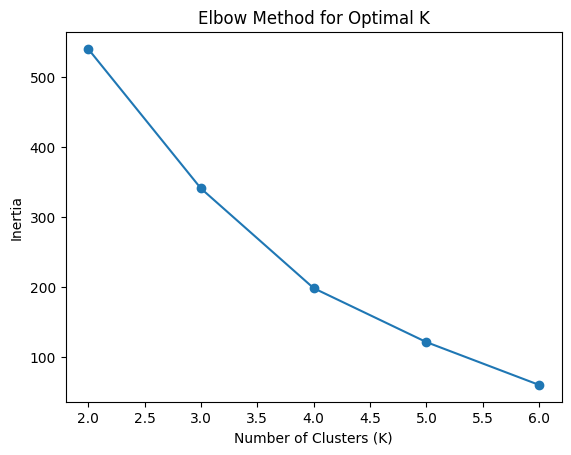

In [55]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []

for k in range(2, 7):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(segmentation_scaled)
    inertia.append(kmeans.inertia_)

plt.plot(range(2, 7), inertia, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal K')
plt.show()

-----Create 3 clusters-----

In [56]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(segmentation_scaled)

print(df['Cluster'].value_counts())

Cluster
1    174
2    117
0     59
Name: count, dtype: int64


-----Analyzing Each Clusters-----

In [57]:
cluster_summary = df.groupby('Cluster')[
    ['Total Spend',
     'Items Purchased',
     'Average Rating',
     'Days Since Last Purchase']
].mean()

print(cluster_summary)

         Total Spend  Items Purchased  Average Rating  \
Cluster                                                 
0        1455.549153        19.949153        4.808475   
1         545.722414         9.540230        3.525862   
2         983.337607        13.444444        4.354701   

         Days Since Last Purchase  
Cluster                            
0                       11.288136  
1                       36.241379  
2                       19.948718  


-----Adding the Segments Names-----

In [58]:
cluster_labels = {
    0: 'Occasional',
    1: 'Premium',
    2: 'Regular'
}

df['Customer Segment'] = df['Cluster'].map(cluster_labels)

print(df['Customer Segment'].value_counts())

Customer Segment
Premium       174
Regular       117
Occasional     59
Name: count, dtype: int64


In [59]:
print("E-Commerce Customer Analysis")
print("Customer Segmentation Prediction")

E-Commerce Customer Analysis
Customer Segmentation Prediction


-----Taking User Input-----

In [60]:
age = int(input("Enter Age: "))
total_spend = float(input("Enter Total Spend: "))
items = int(input("Enter Items Purchased: "))
rating = float(input("Enter Average Rating: "))
days = int(input("Enter Days Since Last Purchase: "))

print("\nData entered successfully!")
print("Age:", age)
print("Total Spend:", total_spend)
print("Items Purchased:", items)
print("Rating:", rating)
print("Days Since Last Purchase:", days)

Enter Age: 24
Enter Total Spend: 30000
Enter Items Purchased: 43
Enter Average Rating: 4.5
Enter Days Since Last Purchase: 15

Data entered successfully!
Age: 24
Total Spend: 30000.0
Items Purchased: 43
Rating: 4.5
Days Since Last Purchase: 15


-----Preparing the prediction model-----

In [61]:
from sklearn.cluster import KMeans

X_segment = df[['Total Spend', 'Items Purchased', 'Average Rating', 'Days Since Last Purchase']]

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

kmeans.fit(X_segment)

print("Customer segmentation model is ready!")

Customer segmentation model is ready!


-----Predicting the customer's cluster-----

In [62]:
new_customer = [[total_spend, items, rating, days]]

cluster = kmeans.predict(new_customer)[0]

print("Predicted Cluster:", cluster)

Predicted Cluster: 1


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


-----Checking the actual clusters from the dataset-----

In [63]:
print("Cluster Centers:")
print(kmeans.cluster_centers_)

Cluster Centers:
[[ 473.3887931     8.49137931    3.325        31.61206897]
 [1311.14444444   17.61538462    4.67521368   17.94017094]
 [ 748.43247863   11.65811966    4.05128205   30.25641026]]


-----Convertion of cluster number into customer type-----

In [64]:
if cluster == 0:
    customer_type = "Occasional"
elif cluster == 1:
    customer_type = "Premium"
else:
    customer_type = "Regular"

print("Customer Type:", customer_type)

Customer Type: Premium


-----Using the Customer type instead of cluster number-----

In [65]:
new_customer = pd.DataFrame({
    'Total Spend': [total_spend],
    'Items Purchased': [items],
    'Average Rating': [rating],
    'Days Since Last Purchase': [days]
})

cluster = kmeans.predict(new_customer)[0]

if cluster == 0:
    customer_type = "Occasional"
elif cluster == 1:
    customer_type = "Premium"
else:
    customer_type = "Regular"

print("Customer Type:", customer_type)

Customer Type: Premium


-----FINAL CUSTOMER TYPE PREDICTION-----

In [66]:
print("===================================")
print("   E-COMMERCE CUSTOMER ANALYSIS")
print("===================================")

total_spend = float(input("Enter Total Spend: "))
items = int(input("Enter Items Purchased: "))
rating = float(input("Enter Average Rating: "))
days = int(input("Enter Days Since Last Purchase: "))

new_customer = pd.DataFrame({
    'Total Spend': [total_spend],
    'Items Purchased': [items],
    'Average Rating': [rating],
    'Days Since Last Purchase': [days]
})

cluster = kmeans.predict(new_customer)[0]

if cluster == 0:
    customer_type = "Occasional"
elif cluster == 1:
    customer_type = "Premium"
else:
    customer_type = "Regular"

print("\n===================================")
print("       CUSTOMER PREDICTION")
print("===================================")
print("Customer Type:", customer_type)
print("===================================")

   E-COMMERCE CUSTOMER ANALYSIS
Enter Total Spend: 30000
Enter Items Purchased: 23
Enter Average Rating: 4.5
Enter Days Since Last Purchase: 14

       CUSTOMER PREDICTION
Customer Type: Premium
